<a href="https://colab.research.google.com/github/abdulghaffark2425/Datheon_Python_Programming_Internship/blob/main/Task04_NLP_Sentiment_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Task 04 Metrics ===
Accuracy: 1.0
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        20
    positive       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



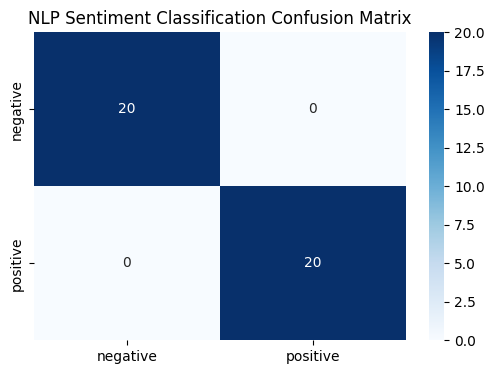

In [1]:
# =========================================================
# DATHEON ML INTERNSHIP - TASK 04
# NLP Sentiment Classification on Customer Reviews (TF-IDF)
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Sample Dataset
data = {
    'review': [
        "Great product, excellent quality and fast shipping!",
        "Terrible experience. Item arrived damaged and customer support was useless.",
        "Loved it! Works perfectly as advertised.",
        "Worst purchase ever. Completely waste of money.",
        "Decent product for the price. Fast delivery.",
        "Horrible service, highly disappointed.",
        "Awesome performance! Highly recommended to everyone.",
        "Poor quality, broke down within two days.",
        "Very satisfied with the item, will buy again.",
        "Not good, bad quality and slow shipping."
    ] * 20,
    'sentiment': ['positive', 'negative', 'positive', 'negative', 'positive', 'negative', 'positive', 'negative', 'positive', 'negative'] * 20
}

df = pd.DataFrame(data)

X_train, X_test, y_train, y_test = train_test_split(df['review'], df['sentiment'], test_size=0.20, random_state=42, stratify=df['sentiment'])

# TF-IDF Vectorization
tfidf = TfidfVectorizer(stop_words='english', max_features=1000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Models
nb = MultinomialNB().fit(X_train_tfidf, y_train)
lr = LogisticRegression().fit(X_train_tfidf, y_train)

y_pred = lr.predict(X_test_tfidf)

print("=== Task 04 Metrics ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Confusion Matrix Plot
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
plt.title("NLP Sentiment Classification Confusion Matrix")
plt.show()